# MÔ HÌNH 1: K-MEANS CLUSTERING (BASELINE TRÊN DỮ LIỆU SẠCH CƠ BẢN)
**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)

Notebook này thực hiện huấn luyện và kiểm thử mô hình cơ sở (**Baseline**) K-Means ($K=3$) **trên tập dữ liệu giao dịch sạch cơ bản** (`data/train.csv`, `data/valid.csv`, `data/test.csv`) **chưa qua rút trích đặc trưng RFM**:
- **Dữ liệu đầu vào:** Tập dữ liệu giao dịch đã làm sạch sau giai đoạn EDA.
- **Thuộc tính cơ bản sử dụng:** `Quantity`, `Price`, `TotalPrice`.
- **Mục tiêu:** Xây dựng mốc đối chuẩn cơ sở (Benchmark) trên 3 tập **Train - Validation - Test** với các thuộc tính thô/cơ bản trước khi so sánh với mô hình phân cụm nâng cao trên bộ chỉ số RFM ở các giai đoạn sau.

In [1]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

PROJECT_ROOT = current
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

from Source.init import PATH_EXPERIMENT_LOG

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Môi trường sẵn sàng tại thư mục gốc: {os.getcwd()}")
print(f"📋 Đường dẫn file nhật ký thực nghiệm: {PATH_EXPERIMENT_LOG}")

✅ Môi trường sẵn sàng tại thư mục gốc: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy
📋 Đường dẫn file nhật ký thực nghiệm: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy\Experiment_Log_Comparison.csv


### 1. Nạp tập dữ liệu giao dịch sạch cơ bản (Train / Validation / Test)
Nạp dữ liệu từ các file `data/train.csv`, `data/valid.csv`, `data/test.csv` đã được phân chia theo `CustomerID` sau bước làm sạch EDA.

In [2]:
train_df = pd.read_csv("data/train.csv")
val_df = pd.read_csv("data/valid.csv")
test_df = pd.read_csv("data/test.csv")

print(f"📊 Tập Train:      {train_df.shape[0]:,} dòng giao dịch")
print(f"📊 Tập Validation: {val_df.shape[0]:,} dòng giao dịch")
print(f"📊 Tập Test:       {test_df.shape[0]:,} dòng giao dịch")

print("\n\n--- 5 Dòng dữ liệu giao dịch Train mẫu ---")
print(train_df[['CustomerID', 'Quantity', 'Price', 'TotalPrice', 'Country']].head())

📊 Tập Train:      251,501 dòng giao dịch
📊 Tập Validation: 72,685 dòng giao dịch
📊 Tập Test:       74,785 dòng giao dịch


--- 5 Dòng dữ liệu giao dịch Train mẫu ---
   CustomerID  Quantity  Price  TotalPrice         Country
0       13085        12   6.95        83.4  United Kingdom
1       13085        12   6.75        81.0  United Kingdom
2       13085        12   6.75        81.0  United Kingdom
3       13085        48   2.10       100.8  United Kingdom
4       13085        24   1.25        30.0  United Kingdom


### 2. Chuẩn hóa thang đo (StandardScaler) trên các thuộc tính cơ bản
Chọn 3 thuộc tính số cơ bản của giao dịch: `['Quantity', 'Price', 'TotalPrice']`.
- **Nguyên tắc chống rò rỉ dữ liệu:** `StandardScaler` chỉ gọi `fit_transform()` trên tập Train, sau đó dùng chính scaler này để `transform()` trên tập Validation và Test.

In [3]:
features = ['Quantity', 'Price', 'TotalPrice']

X_train_raw = train_df[features]
X_val_raw = val_df[features]
X_test_raw = test_df[features]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)
X_test_scaled = scaler.transform(X_test_raw)

print("✅ Đã chuẩn hóa dữ liệu giao dịch cơ bản:")
print("   - Mean (Train):", scaler.mean_.round(3))
print("   - Scale/Std (Train):", scaler.scale_.round(3))

✅ Đã chuẩn hóa dữ liệu giao dịch cơ bản:
   - Mean (Train): [12.607  2.923 21.93 ]
   - Scale/Std (Train): [31.994  2.947 62.066]


### 3. Huấn luyện mô hình K-Means Baseline ($K=3$) trên tập Train
Khởi tạo và huấn luyện mô hình K-Means với các thông số mặc định cơ bản:
- `n_clusters = 3`
- `init = 'k-means++'`
- `n_init = 10`
- `random_state = 42`

In [4]:
k_baseline = 3
kmeans_baseline = KMeans(n_clusters=k_baseline, init='k-means++', n_init=10, random_state=42)

# Huấn luyện mô hình trên tập Train
train_labels = kmeans_baseline.fit_predict(X_train_scaled)
train_df['Cluster'] = train_labels

print(f"✅ Đã huấn luyện xong K-Means Baseline K={k_baseline} trên tập Train!")

✅ Đã huấn luyện xong K-Means Baseline K=3 trên tập Train!


### 4. Đánh giá chất lượng phân cụm trên cả 3 tập: Train, Validation và Test
Tính toán các chỉ số nội tại:
1. **Silhouette Score:** Đo độ gắn kết nội cụm và phân tách ngoại cụm (sử dụng mẫu đại diện ngẫu nhiên `sample_size=10,000` để tính toán nhanh chóng).
2. **Davies-Bouldin Index:** Tỷ số mức độ phân tán nội cụm trên khoảng cách giữa các tâm cụm (càng nhỏ càng tốt).
3. **Calinski-Harabasz Index:** Tỷ số phương sai liên cụm trên phương sai nội cụm (càng lớn càng tốt).

In [5]:
# 1. Dự đoán nhãn cụm cho Validation và Test dựa theo tâm cụm đã học từ Train
val_labels = kmeans_baseline.predict(X_val_scaled)
test_labels = kmeans_baseline.predict(X_test_scaled)

val_df['Cluster'] = val_labels
test_df['Cluster'] = test_labels

# 2. Đánh giá trên tập Train
sil_train = silhouette_score(X_train_scaled, train_labels, sample_size=10000, random_state=42)
db_train = davies_bouldin_score(X_train_scaled, train_labels)
ch_train = calinski_harabasz_score(X_train_scaled, train_labels)

# 3. Đánh giá trên tập Validation
sil_val = silhouette_score(X_val_scaled, val_labels, sample_size=10000, random_state=42)
db_val = davies_bouldin_score(X_val_scaled, val_labels)
ch_val = calinski_harabasz_score(X_val_scaled, val_labels)

# 4. Đánh giá trên tập Test
sil_test = silhouette_score(X_test_scaled, test_labels, sample_size=10000, random_state=42)
db_test = davies_bouldin_score(X_test_scaled, test_labels)
ch_test = calinski_harabasz_score(X_test_scaled, test_labels)

print("=" * 70)
print(f"📊 BẢNG KẾT QUẢ ĐÁNH GIÁ K-MEANS BASELINE (K={k_baseline}) TRÊN DỮ LIỆU SẠCH CƠ BẢN:")
print("=" * 70)
print(f"Tập Huấn luyện (Train):      Silhouette = {sil_train:.4f} | Davies-Bouldin = {db_train:.4f} | Calinski-Harabasz = {ch_train:,.2f}")
print(f"Tập Kiểm định (Validation):  Silhouette = {sil_val:.4f} | Davies-Bouldin = {db_val:.4f} | Calinski-Harabasz = {ch_val:,.2f}")
print(f"Tập Kiểm thử (Test):         Silhouette = {sil_test:.4f} | Davies-Bouldin = {db_test:.4f} | Calinski-Harabasz = {ch_test:,.2f}")
print("=" * 70)

📊 BẢNG KẾT QUẢ ĐÁNH GIÁ K-MEANS BASELINE (K=3) TRÊN DỮ LIỆU SẠCH CƠ BẢN:
Tập Huấn luyện (Train):      Silhouette = 0.6244 | Davies-Bouldin = 0.6626 | Calinski-Harabasz = 150,925.86
Tập Kiểm định (Validation):  Silhouette = 0.6175 | Davies-Bouldin = 0.6215 | Calinski-Harabasz = 46,703.92
Tập Kiểm thử (Test):         Silhouette = 0.6417 | Davies-Bouldin = 0.6040 | Calinski-Harabasz = 46,310.08


### 5. Phân tích chân dung các cụm giao dịch (Cluster Profiling)
Thống kê số lượng bản ghi và giá trị trung bình của `Quantity`, `Price`, `TotalPrice` theo từng cụm trên tập Train.

In [6]:
profile = train_df.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Quantity': 'mean',
    'Price': 'mean',
    'TotalPrice': 'mean'
}).rename(columns={'CustomerID': 'SoLuong_BanGhi'})

profile['TyLe_%'] = (profile['SoLuong_BanGhi'] / len(train_df) * 100).round(2)
profile['Quantity'] = profile['Quantity'].round(2)
profile['Price'] = profile['Price'].round(2)
profile['TotalPrice'] = profile['TotalPrice'].round(2)

print("--- THỐNG KÊ ĐẶC TRƯNG CỤM GIAO DỊCH CƠ BẢN (TẬP TRAIN) ---")
print(profile[['SoLuong_BanGhi', 'TyLe_%', 'Quantity', 'Price', 'TotalPrice']])

--- THỐNG KÊ ĐẶC TRƯNG CỤM GIAO DỊCH CƠ BẢN (TẬP TRAIN) ---
         SoLuong_BanGhi  TyLe_%  Quantity  Price  TotalPrice
Cluster                                                     
0                212862   84.64     11.24   1.96       16.22
1                  2503    1.00    258.76   2.10      409.34
2                 36136   14.37      3.60   8.67       28.72


### 6. Đánh giá thuộc tính nào đóng góp nhiều nhất vào việc phân cụm
Để biết mô hình K-Means gom cụm dựa trên thuộc tính nào nhiều nhất, chúng ta sử dụng 2 phương pháp định lượng:
1. **Độ phân tách tâm cụm (Centroid Dispersion):** Đo độ lệch chuẩn (Std) của tọa độ các tâm cụm trên không gian đã chuẩn hóa (Z-score). Thuộc tính nào có các tâm cụm cách xa nhau nhất chứng tỏ thuộc tính đó phân tách các cụm mạnh nhất.
2. **Kiểm định ANOVA F-Score (`f_classif`):** Đo tỷ số phương sai giữa các cụm trên phương sai nội cụm để tính chính xác tỷ lệ % mức độ đóng góp của từng thuộc tính.

📊 BẢNG XẾP HẠNG THUỘC TÍNH ĐÓNG GÓP NHIỀU NHẤT VÀO GOM CỤM:
   Thuộc tính  Độ phân tách tâm cụm (Std)  ANOVA F-Score  Tỷ lệ đóng góp (%)
0       Price                      1.0625      221473.04               44.80
1    Quantity                      3.7045      190218.19               38.48
2  TotalPrice                      2.9395       82663.99               16.72
👉 KẾT LUẬN: Mô hình K-Means gom cụm dựa trên thuộc tính [Price] nhiều nhất (44.8%).


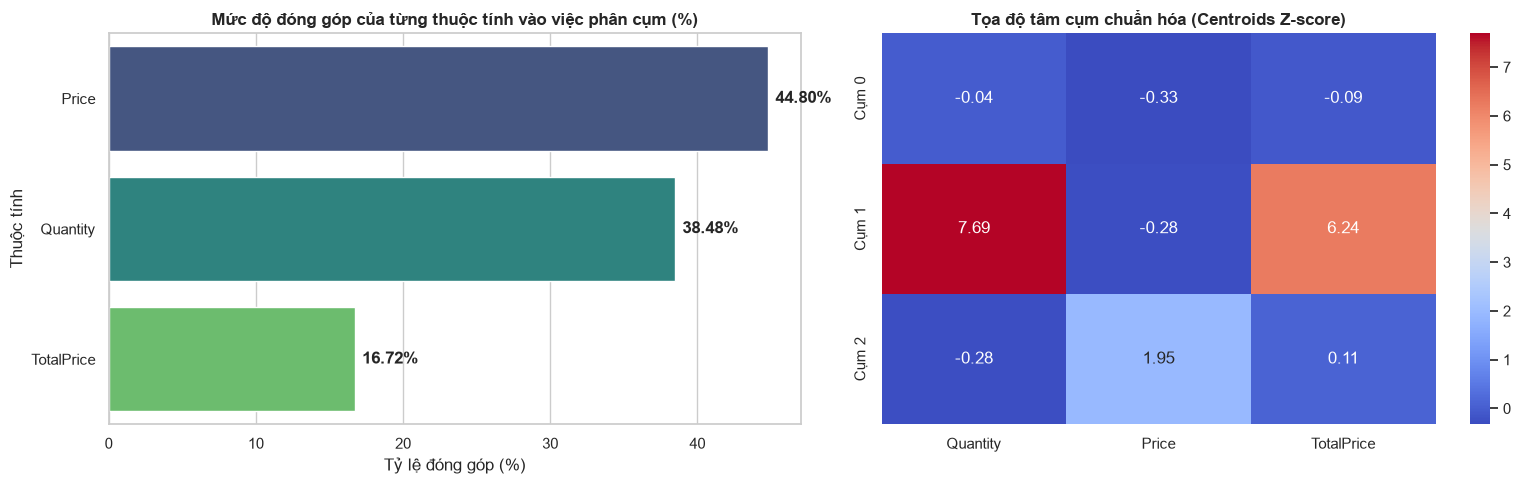

In [7]:
from sklearn.feature_selection import f_classif

# 1. Trích xuất tọa độ tâm cụm (trên không gian chuẩn hóa Z-score)
centers = kmeans_baseline.cluster_centers_
df_centers = pd.DataFrame(centers, columns=features, index=[f"Cụm {i}" for i in range(k_baseline)])

# 2. Tính độ lệch chuẩn (Std) giữa các tâm cụm theo từng thuộc tính
centroid_std = np.std(centers, axis=0)

# 3. Tính chỉ số ANOVA F-Score để đo mức độ phân biệt giữa các cụm
f_scores, p_values = f_classif(X_train_scaled, train_labels)
feature_importance = (f_scores / f_scores.sum()) * 100

# 4. Tổng hợp bảng xếp hạng mức độ ảnh hưởng của các thuộc tính
ranking_df = pd.DataFrame({
    'Thuộc tính': features,
    'Độ phân tách tâm cụm (Std)': centroid_std.round(4),
    'ANOVA F-Score': f_scores.round(2),
    'Tỷ lệ đóng góp (%)': feature_importance.round(2)
}).sort_values(by='Tỷ lệ đóng góp (%)', ascending=False).reset_index(drop=True)

print("=" * 65)
print("📊 BẢNG XẾP HẠNG THUỘC TÍNH ĐÓNG GÓP NHIỀU NHẤT VÀO GOM CỤM:")
print("=" * 65)
print(ranking_df)
print("=" * 65)

top_feature = ranking_df.iloc[0]['Thuộc tính']
top_percent = ranking_df.iloc[0]['Tỷ lệ đóng góp (%)']
print(f"👉 KẾT LUẬN: Mô hình K-Means gom cụm dựa trên thuộc tính [{top_feature}] nhiều nhất ({top_percent}%).")

# 5. Trực quan hóa mức độ đóng góp và tọa độ tâm cụm
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ thanh tỷ lệ đóng góp
sns.barplot(data=ranking_df, x='Tỷ lệ đóng góp (%)', y='Thuộc tính', palette='viridis', ax=ax1)
ax1.set_title("Mức độ đóng góp của từng thuộc tính vào việc phân cụm (%)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Tỷ lệ đóng góp (%)")
for i, v in enumerate(ranking_df['Tỷ lệ đóng góp (%)']):
    ax1.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold')

# Biểu đồ Heatmap tọa độ tâm cụm (Z-score)
sns.heatmap(df_centers, annot=True, cmap="coolwarm", fmt=".2f", ax=ax2, cbar=True)
ax2.set_title("Tọa độ tâm cụm chuẩn hóa (Centroids Z-score)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()


### 7. Trực quan hóa phân cụm (2D PCA Visualization & Biểu đồ đặc trưng)
Giảm chiều không gian 3 thuộc tính cơ bản về 2D bằng PCA trên tập mẫu đại diện để quan sát sự phân bố.

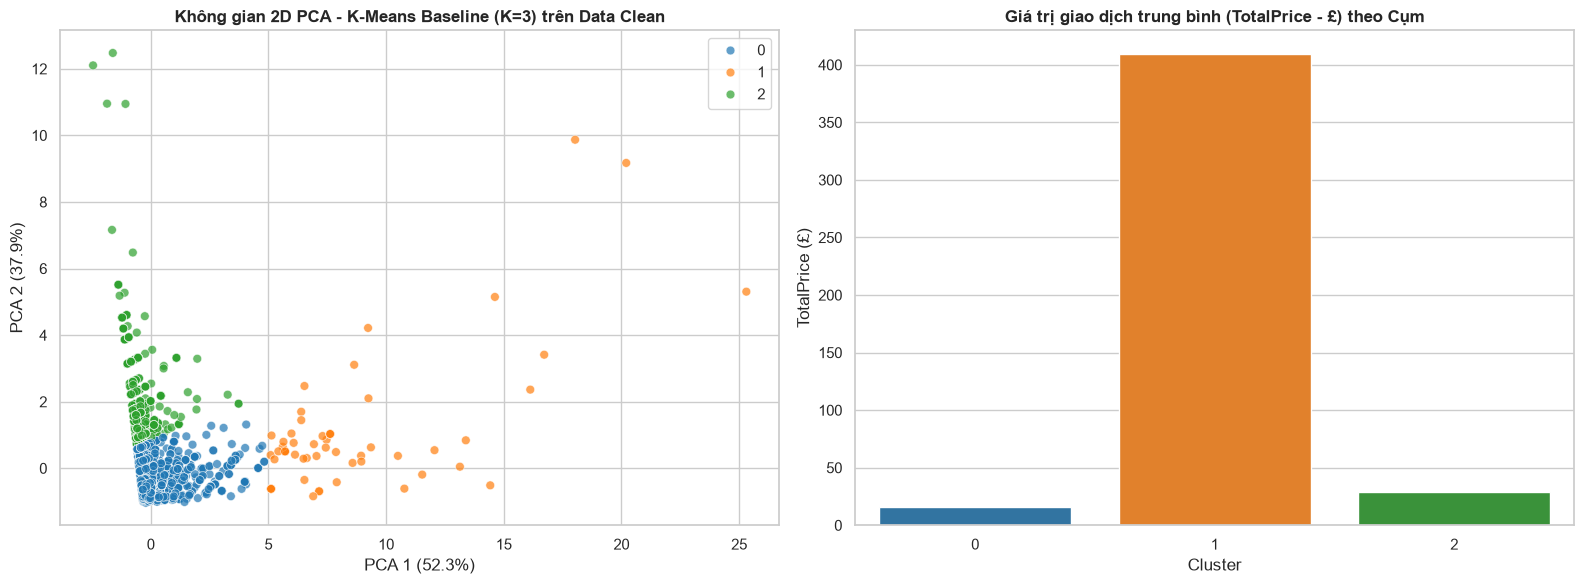

In [8]:
# Lấy sample 5,000 dòng để vẽ trực quan nhanh chóng
sample_size = min(5000, len(X_train_scaled))
np.random.seed(42)
sample_idx = np.random.choice(len(X_train_scaled), size=sample_size, replace=False)

pca = PCA(n_components=2, random_state=42)
X_sample_pca = pca.fit_transform(X_train_scaled[sample_idx])
sample_labels = train_labels[sample_idx]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Scatter PCA 2D
sns.scatterplot(
    x=X_sample_pca[:, 0], y=X_sample_pca[:, 1], hue=sample_labels,
    palette='tab10', alpha=0.7, s=40, ax=ax1
)
ax1.set_title(f"Không gian 2D PCA - K-Means Baseline (K={k_baseline}) trên Data Clean", fontsize=12, fontweight='bold')
ax1.set_xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
ax1.set_ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")

# Biểu đồ cột TotalPrice trung bình theo Cụm
sns.barplot(data=profile.reset_index(), x='Cluster', y='TotalPrice', palette='tab10', ax=ax2)
ax2.set_title("Giá trị giao dịch trung bình (TotalPrice - £) theo Cụm", fontsize=12, fontweight='bold')
ax2.set_ylabel("TotalPrice (£)")

plt.tight_layout()
plt.show()

### 8. Ghi nhận kết quả vào nhật ký thực nghiệm `Experiment_Log_Comparison.csv`


In [9]:
now_str = dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S")

entries = [
    {
        'Timestamp': now_str,
        'Model': f"K-Means Baseline (K={k_baseline}, Data Clean) - Train",
        'Silhouette': round(sil_train, 4),
        'Davies-Bouldin': round(db_train, 4),
        'Calinski-Harabasz': round(ch_train, 2)
    },
    {
        'Timestamp': now_str,
        'Model': f"K-Means Baseline (K={k_baseline}, Data Clean) - Validation",
        'Silhouette': round(sil_val, 4),
        'Davies-Bouldin': round(db_val, 4),
        'Calinski-Harabasz': round(ch_val, 2)
    },
    {
        'Timestamp': now_str,
        'Model': f"K-Means Baseline (K={k_baseline}, Data Clean) - Test",
        'Silhouette': round(sil_test, 4),
        'Davies-Bouldin': round(db_test, 4),
        'Calinski-Harabasz': round(ch_test, 2)
    }
]

df_entries = pd.DataFrame(entries)

if not os.path.exists(PATH_EXPERIMENT_LOG):
    df_entries.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='w')
else:
    df_entries.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='a', header=False)

print(f"💾 Đã lưu thành công 3 kết quả thực nghiệm vào: {PATH_EXPERIMENT_LOG}")
print(df_entries)

💾 Đã lưu thành công 3 kết quả thực nghiệm vào: C:\Users\Quân\Desktop\ml_group\Do_an_CuoiKy\Experiment_Log_Comparison.csv
             Timestamp                                            Model  \
0  2026-11-23 14:24:02       K-Means Baseline (K=3, Data Clean) - Train   
1  2026-11-23 14:24:02  K-Means Baseline (K=3, Data Clean) - Validation   
2  2026-11-23 14:24:02        K-Means Baseline (K=3, Data Clean) - Test   

   Silhouette  Davies-Bouldin  Calinski-Harabasz  
0      0.6244          0.6626          150925.86  
1      0.6175          0.6215           46703.92  
2      0.6417          0.6040           46310.08  


---
## TỔNG KẾT MÔ HÌNH K-MEANS BASELINE TRÊN DATA CLEAN CƠ BẢN
- Đã hoàn tất huấn luyện, kiểm định và kiểm thử mô hình cơ sở K-Means ($K=3$) trên dữ liệu giao dịch sạch cơ bản (`Quantity`, `Price`, `TotalPrice`).
- Kết quả này thiết lập mốc so sánh (Benchmark) thô ban đầu để đối chứng với hiệu năng khi ứng dụng bộ chỉ số RFM (Recency, Frequency, Monetary) trong các giai đoạn tiếp theo.